# E91 Rainbow-style DQN with action masking (DIQKD analog of `QKD_experiment_7`)

**Why value-based here**: in `QKD_experiment_5_E91` vanilla PPO collapsed because random policy-gradient exploration violates the near-cliff CHSH constraint. DQN is off-policy with a replay buffer — it can re-use past safe trajectories and learn Q-values for each discrete action, which is more robust than online policy-gradient updates under sparse violation rewards.

We use two value-based / masked methods:
- **MaskablePPO** (from `sb3-contrib`): on-policy with feasibility action masking via the Oracle's projected-windowed-mean filter.
- **Rainbow-DQN-lite** (custom): Double-DQN + Dueling architecture + n-step returns + ε-greedy with action masking. Mirrors BB84 `QKD_experiment_7.ipynb`.

Compared against:
- **DP (analytical)** — Bellman-optimal over library
- **Oracle (greedy)** — windowed-projected feasibility
- **Identity** — honest Bell pair

Same library as `QKD_experiment_5_E91.ipynb` (7 levels × 4 anchors = 26 cells + identity).

## Imports

In [1]:
import os, math, pickle, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import gymnasium as gym
from gymnasium import spaces
from stable_baselines3.common.callbacks import BaseCallback
import torch.nn as nn
import torch.nn.functional as F
from collections import deque
from sb3_contrib import MaskablePPO

import pathB_lib as L
from pathB_lib import (DET_THRESH, P_INTERP, EPISODE_LEN, P_MU, P_KAPPA, P_SIGMA,
                       P_MIN, P_MAX, WIN_S, PathBEnv, run_episode, summarize_runs,
                       compute_holevo_and_S_noisy)
from numpy.polynomial.hermite_e import hermegauss

torch.set_default_dtype(torch.float32)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## Config + 7-level library

In [2]:
from evoluspsa_e91 import circuit_to_unitary, STD_SETTINGS
library = pickle.load(open('e91_library_pathB_7levels.pkl', 'rb'))
torch.set_default_dtype(torch.float64)
C_dt = torch.complex128

phi_plus_e0 = torch.zeros(8, dtype=C_dt)
phi_plus_e0[0] = 1 / math.sqrt(2); phi_plus_e0[6] = 1 / math.sqrt(2)
M_init = torch.randn(8, 8, dtype=C_dt) + 1j * torch.randn(8, 8, dtype=C_dt)
M_init[:, 0] = phi_plus_e0
Q, _ = torch.linalg.qr(M_init); Q[:, 0] = phi_plus_e0
U_star = Q

action_U = [U_star]
action_settings = [np.array(STD_SETTINGS)]
action_meta = [{'label': 'identity', 'lvl': None, 'p_anchor': None}]
for (p_anchor, lvl), entry in library.items():
    action_U.append(circuit_to_unitary(entry['circuit']))
    action_settings.append(np.array(entry['settings']))
    action_meta.append({'label': f'{lvl}_p{p_anchor:.3f}', 'lvl': lvl, 'p_anchor': p_anchor})
N_ACTIONS = len(action_U)

S_TBL = np.zeros((N_ACTIONS, len(P_INTERP)))
CHI_TBL = np.zeros((N_ACTIONS, len(P_INTERP)))
for a in range(N_ACTIONS):
    for j, p in enumerate(P_INTERP):
        S, chi = compute_holevo_and_S_noisy(action_U[a], action_settings[a], float(p))
        S_TBL[a, j] = S; CHI_TBL[a, j] = chi
torch.set_default_dtype(torch.float32)
print(f'N_ACTIONS = {N_ACTIONS}')
print(f'DET_THRESH = {DET_THRESH:.4f}')

N_ACTIONS = 27
DET_THRESH = 2.4440


## Maskable env

Subclass `PathBEnv` to add an `action_masks()` method that returns a boolean array indicating which actions keep the projected windowed-mean S above DET_THRESH at the current step. MaskablePPO consumes these masks and sets logits of masked actions to −∞.

In [3]:
env_kwargs = dict(viol_coef=3.0, det_penalty=30.0, augmented_obs=True)

class MaskedPathBEnv(PathBEnv):
    def __init__(self, **kwargs):
        super().__init__(S_TBL, CHI_TBL, **kwargs)
    def action_masks(self):
        past = self.S_ep[-(WIN_S - 1):] if hasattr(self, 'S_ep') else []
        sum_past = float(np.sum(past)) if past else 0.0
        n = len(past) + 1
        mask = np.zeros(self.N, dtype=bool)
        for a in range(self.N):
            S_a = self.S_at(a, self.p)
            if (sum_past + S_a)/n >= DET_THRESH - 1e-3:
                mask[a] = True
        if not mask.any():
            best = int(np.argmax([self.S_at(a, self.p) for a in range(self.N)]))
            mask[best] = True
        return mask

## DP (analytical reference)

In [4]:
N_PBIN = len(P_INTERP); P_BINS = P_INTERP
def run_dp(N_SBIN=250, DET_PEN=30.0, T=EPISODE_LEN):
    S_BINS = np.linspace(0, T*2*math.sqrt(2)+5, N_SBIN)
    GH_NODES, GH_W = hermegauss(7); GH_W = GH_W / np.sqrt(2*math.pi)
    decay = np.exp(-P_KAPPA)
    noise_std = P_SIGMA * np.sqrt((1 - np.exp(-2*P_KAPPA)) / (2*P_KAPPA))
    TRANS_p = np.zeros((N_PBIN, len(GH_NODES)), dtype=np.int32)
    TRANS_w = np.zeros((N_PBIN, len(GH_NODES)))
    for i in range(N_PBIN):
        p_mean = P_MU + (P_BINS[i] - P_MU) * decay
        for k, (n, w) in enumerate(zip(GH_NODES, GH_W)):
            p_next = float(np.clip(p_mean + noise_std*n, P_MIN, P_MAX))
            TRANS_p[i, k] = int(np.argmin(np.abs(P_BINS - p_next)))
            TRANS_w[i, k] = w
    V = np.zeros((T+1, N_PBIN, N_SBIN)); PI = np.zeros((T, N_PBIN, N_SBIN), dtype=np.int8)
    budget = T * DET_THRESH
    for s_idx in range(N_SBIN):
        if S_BINS[s_idx] < budget: V[T, :, s_idx] = -DET_PEN
    for t in range(T-1, -1, -1):
        EV = np.zeros((N_PBIN, N_SBIN))
        for p_idx in range(N_PBIN):
            for k in range(len(GH_NODES)):
                EV[p_idx] += TRANS_w[p_idx, k] * V[t+1, TRANS_p[p_idx, k], :]
        for p_idx in range(N_PBIN):
            S_acts = S_TBL[:, p_idx]; chi_acts = CHI_TBL[:, p_idx]
            s_new = S_BINS[:, None] + S_acts[None, :]
            EV_interp = np.interp(s_new.ravel(), S_BINS, EV[p_idx]).reshape(s_new.shape)
            Q = chi_acts[None, :] + EV_interp
            best_a = np.argmax(Q, axis=1)
            V[t, p_idx, :] = Q[np.arange(N_SBIN), best_a]
            PI[t, p_idx, :] = best_a.astype(np.int8)
    return V, PI, S_BINS
print('Running DP...')
V, PI, S_BINS = run_dp()
print('Done')

Running DP...
Done


## Training — MaskablePPO + DQN

In [5]:
TRAIN_STEPS = 500_000
EVAL_EVERY  = 25_000

def evaluate(model, n_episodes=20, masked=False, rainbow_q=None):
    env = MaskedPathBEnv(**env_kwargs) if (masked or rainbow_q is not None) else PathBEnv(S_TBL, CHI_TBL, **env_kwargs)
    chis, dets = [], 0
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=10_000+ep); done = False
        while not done:
            if rainbow_q is not None:
                # Q-greedy with mask
                mask = env.action_masks()
                with torch.no_grad():
                    q = rainbow_q(torch.tensor(obs, dtype=torch.float32).unsqueeze(0))[0].numpy()
                q[~mask] = -np.inf
                a = int(np.argmax(q))
            elif masked:
                m = env.action_masks()
                a, _ = model.predict(obs, action_masks=m, deterministic=True)
            else:
                a, _ = model.predict(obs, deterministic=True)
            obs, _, done, _, info = env.step(int(a))
        chis.append(np.mean(env.chi_ep))
        if info.get('detected'): dets += 1
    return float(np.mean(chis)), dets/n_episodes


# === MaskablePPO ===
print('=== MaskablePPO (feasibility mask) ===')

class CB(BaseCallback):
    def __init__(self, savename, masked):
        super().__init__()
        self.savename = savename; self.masked = masked
        self.best_score = -1e9; self.history = []
    def _on_step(self):
        if self.num_timesteps % EVAL_EVERY == 0:
            try:
                m, d = evaluate(self.model, n_episodes=20, masked=self.masked)
                self.history.append({'step': self.num_timesteps, 'chi': m, 'det': d})
                score = m - 2.0 * d
                if score > self.best_score and d <= 0.05:
                    self.best_score = score; self.model.save(self.savename)
                if self.num_timesteps % 100_000 == 0:
                    print(f'  [{self.savename} @ {self.num_timesteps:>7,}] χ={m:.4f} det={d*100:.1f}%')
            except Exception as e:
                print(f'  Eval error: {e}')
        return True

train_env_m = MaskedPathBEnv(**env_kwargs)
cb_m = CB('best_mppo_e91', masked=True)
mppo = MaskablePPO('MlpPolicy', train_env_m, verbose=0, device='cpu',
                   learning_rate=3e-4, n_steps=1024, batch_size=64, n_epochs=10,
                   gamma=0.99, ent_coef=0.10, clip_range=0.2, seed=42,
                   policy_kwargs=dict(net_arch=[128, 128]))
t0 = time.time(); mppo.learn(total_timesteps=TRAIN_STEPS, callback=cb_m)
print(f'MaskablePPO trained in {(time.time()-t0)/60:.1f} min')
if os.path.exists('best_mppo_e91.zip'): mppo = MaskablePPO.load('best_mppo_e91')


# === Rainbow-DQN (Double + Dueling + n-step + masking) ===
print('\n=== Rainbow-DQN (Double + Dueling + n-step + masking) ===')

OBS_DIM = 9   # augmented obs (7 base + 2 headroom)
HIDDEN = 128
GAMMA, N_STEP = 0.99, 3
BUFFER_SIZE = 100_000
BATCH = 128
LR = 5e-4
EPS_START, EPS_END, EPS_DECAY = 1.0, 0.02, 200_000
WARMUP, TRAIN_FREQ, TARGET_UPD = 5_000, 4, 1_000

class DuelingQ(nn.Module):
    def __init__(self):
        super().__init__()
        self.feat = nn.Sequential(nn.Linear(OBS_DIM, HIDDEN), nn.ReLU(),
                                  nn.Linear(HIDDEN, HIDDEN), nn.ReLU())
        self.v = nn.Linear(HIDDEN, 1); self.a = nn.Linear(HIDDEN, N_ACTIONS)
    def forward(self, x):
        z = self.feat(x); v = self.v(z); a = self.a(z)
        return v + a - a.mean(dim=-1, keepdim=True)

class NStepBuffer:
    def __init__(self, cap=BUFFER_SIZE, n=N_STEP, gamma=GAMMA):
        self.cap=cap; self.n=n; self.gamma=gamma
        self.obs=np.zeros((cap, OBS_DIM), dtype=np.float32)
        self.no =np.zeros((cap, OBS_DIM), dtype=np.float32)
        self.act=np.zeros(cap, dtype=np.int64)
        self.rew=np.zeros(cap, dtype=np.float32)
        self.dn =np.zeros(cap, dtype=np.float32)
        self.size=0; self.idx=0; self.q=deque(maxlen=n)
    def _store(self, o, a, r, no, d):
        i=self.idx; self.obs[i]=o; self.act[i]=a; self.rew[i]=r; self.no[i]=no; self.dn[i]=d
        self.idx=(i+1)%self.cap; self.size=min(self.size+1, self.cap)
    def add(self, o, a, r, no, d):
        self.q.append((o, a, r, no, d))
        if len(self.q)==self.n:
            o0,a0,_,_,_=self.q[0]; R=0.0; dd=False; lno=no
            for k,(_,_,rk,nok,dk) in enumerate(self.q):
                R+=(self.gamma**k)*rk; lno=nok
                if dk: dd=True; break
            self._store(o0, a0, R, lno, dd)
        if d:
            while len(self.q)>1:
                self.q.popleft()
                o0,a0,_,_,_=self.q[0]; R=0.0; lno=no
                for k,(_,_,rk,nok,_) in enumerate(self.q):
                    R+=(self.gamma**k)*rk; lno=nok
                self._store(o0, a0, R, lno, True)
            self.q.clear()
    def sample(self, b):
        idx=np.random.randint(0, self.size, size=b)
        return (torch.tensor(self.obs[idx]), torch.tensor(self.act[idx]),
                torch.tensor(self.rew[idx]), torch.tensor(self.no[idx]),
                torch.tensor(self.dn[idx]))

q_on = DuelingQ(); q_tg = DuelingQ()
q_tg.load_state_dict(q_on.state_dict()); q_tg.eval()
opt = torch.optim.Adam(q_on.parameters(), lr=LR)
buf = NStepBuffer()

def q_act(obs, eps, mask=None):
    if np.random.random()<eps:
        if mask is None: return int(np.random.randint(N_ACTIONS))
        feasible = np.where(mask)[0]
        return int(np.random.choice(feasible)) if len(feasible) else 0
    with torch.no_grad():
        q = q_on(torch.tensor(obs, dtype=torch.float32).unsqueeze(0))[0].numpy()
    if mask is not None: q[~mask] = -np.inf
    return int(np.argmax(q))

def train_step():
    if buf.size < BATCH: return
    o, a, r, no, d = buf.sample(BATCH)
    q_pred = q_on(o).gather(1, a.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        na = q_on(no).argmax(dim=-1)              # Double DQN
        q_next = q_tg(no).gather(1, na.unsqueeze(1)).squeeze(1)
        target = r + (GAMMA**N_STEP) * (1 - d) * q_next
    loss = F.smooth_l1_loss(q_pred, target)
    opt.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(q_on.parameters(), 10.0); opt.step()

env_r = MaskedPathBEnv(**env_kwargs)
obs, _ = env_r.reset(seed=42)
rainbow_history = []; best_rainbow_score = -1e9
t0 = time.time()
for step in range(1, TRAIN_STEPS+1):
    eps = max(EPS_END, EPS_START - (EPS_START-EPS_END)*step/EPS_DECAY)
    mask = env_r.action_masks()
    a = (int(np.random.choice(np.where(mask)[0])) if step<WARMUP else q_act(obs, eps, mask))
    no, r, done, _, _ = env_r.step(a)
    buf.add(obs, a, r, no, done)
    obs = no
    if done: obs, _ = env_r.reset(seed=42+step)
    if step>=WARMUP and step%TRAIN_FREQ==0: train_step()
    if step%TARGET_UPD==0: q_tg.load_state_dict(q_on.state_dict())
    if step%EVAL_EVERY==0 and step>=WARMUP:
        mchi, drate = evaluate(None, n_episodes=20, rainbow_q=q_on)
        score = mchi - 2.0*drate
        rainbow_history.append({'step': step, 'chi': mchi, 'det': drate})
        if score > best_rainbow_score and drate<=0.05:
            best_rainbow_score = score
            torch.save(q_on.state_dict(), 'best_rainbow_e91.pt')
        if step%100_000==0:
            print(f'  [Rainbow @ {step:>7,}] χ={mchi:.4f} det={drate*100:.1f}% ε={eps:.2f}')
print(f'Rainbow trained in {(time.time()-t0)/60:.1f} min')
if os.path.exists('best_rainbow_e91.pt'):
    q_on.load_state_dict(torch.load('best_rainbow_e91.pt')); q_on.eval()


=== MaskablePPO (feasibility mask) ===


  [best_mppo_e91 @ 100,000] χ=0.3408 det=0.0%


  [best_mppo_e91 @ 200,000] χ=0.3329 det=0.0%


  [best_mppo_e91 @ 300,000] χ=0.3413 det=0.0%


  [best_mppo_e91 @ 400,000] χ=0.3374 det=0.0%


...

  [Rainbow @ 100,000] χ=0.3312 det=0.0% ε=0.51


  [Rainbow @ 200,000] χ=0.3329 det=0.0% ε=0.02


  [Rainbow @ 300,000] χ=0.3198 det=0.0% ε=0.02


  [Rainbow @ 400,000] χ=0.3385 det=0.0% ε=0.02


  [Rainbow @ 500,000] χ=0.3250 det=0.0% ε=0.02
Rainbow trained in 7.5 min


## Evaluation

In [6]:
def mppo_policy(obs, env):
    mask = env.action_masks() if hasattr(env, 'action_masks') else None
    if mask is not None:
        a, _ = mppo.predict(obs, action_masks=mask, deterministic=True)
    else:
        a, _ = mppo.predict(obs, deterministic=True)
    return int(a)

def rainbow_policy(obs, env):
    mask = env.action_masks() if hasattr(env, "action_masks") else None
    with torch.no_grad():
        q = q_on(torch.tensor(obs, dtype=torch.float32).unsqueeze(0))[0].numpy()
    if mask is not None: q[~mask] = -np.inf
    return int(np.argmax(q))

def dp_policy(obs, env):
    p_idx = int(np.argmin(np.abs(P_BINS - float(obs[0]))))
    s_idx = int(np.argmin(np.abs(S_BINS - float(np.sum(env.S_ep)))))
    return int(PI[env.t, p_idx, s_idx])

def oracle_policy(obs, env):
    p_now = float(obs[0])
    past = env.S_ep[-(WIN_S - 1):]
    sum_past = float(np.sum(past)) if past else 0.0
    n = len(past) + 1
    best_a, best_chi = 0, -np.inf
    for a in range(N_ACTIONS):
        S_a = float(np.interp(p_now, P_INTERP, S_TBL[a]))
        chi_a = float(np.interp(p_now, P_INTERP, CHI_TBL[a]))
        if (sum_past + S_a)/n >= DET_THRESH and chi_a > best_chi:
            best_chi = chi_a; best_a = a
    if best_chi < 0:
        best_a = int(np.argmax([float(np.interp(p_now, P_INTERP, S_TBL[a])) for a in range(N_ACTIONS)]))
    return best_a

def identity_policy(obs, env): return 0

POLICIES = {'MaskablePPO': mppo_policy, 'Rainbow-DQN': rainbow_policy,
            'DP': dp_policy, 'Oracle': oracle_policy, 'Identity': identity_policy}

TEST_EPS = 200
results = {}
for name, pol in POLICIES.items():
    runs = []
    for ep in range(TEST_EPS):
        env = MaskedPathBEnv(**env_kwargs) if name in ('MaskablePPO', 'Rainbow-DQN') else PathBEnv(S_TBL, CHI_TBL, **env_kwargs)
        runs.append(run_episode(env, pol, env_seed=20_000+ep))
    summary = summarize_runs(runs)
    actions = np.concatenate([r['actions'] for r in runs])
    results[name] = {'summary': summary, 'actions': actions.tolist(),
                     'n_unique': len(np.unique(actions))}

rows = []
for name, r in results.items():
    s = r['summary']
    rows.append({'Method': name,
                 'Mean χ': f"{s['mean_chi']:.4f}",
                 'Std χ':  f"{s['std_chi']:.4f}",
                 'Mean S': f"{s['mean_S']:.4f}",
                 'Det %':  f"{s['det_rate']*100:.1f}%",
                 'Distinct actions': r['n_unique']})
pd.DataFrame(rows).set_index('Method')

,Mean χ,Std χ,Mean S,Det %,Distinct actions
Method,,,,,
MaskablePPO,0.3467,0.0653,2.4484,0.0%,14
Rainbow-DQN,0.3484,0.0652,2.4471,0.0%,14
DP,0.3540,0.0629,2.4483,7.0%,24
Oracle,0.3507,0.0668,2.4463,0.0%,17
Identity,0.0000,0.0000,2.6613,0.0%,1


## Plots

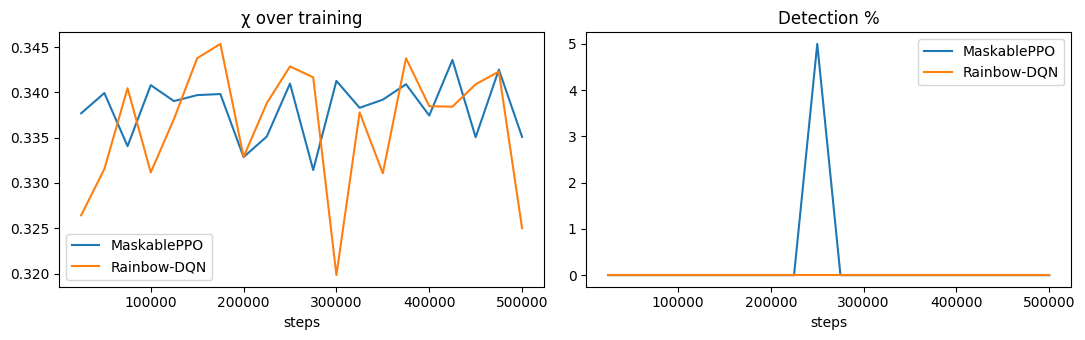

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
if cb_m.history:
    h = pd.DataFrame(cb_m.history)
    axes[0].plot(h['step'], h['chi'], label='MaskablePPO')
    axes[1].plot(h['step'], h['det']*100, label='MaskablePPO')
if rainbow_history:
    h = pd.DataFrame(rainbow_history)
    axes[0].plot(h['step'], h['chi'], label='Rainbow-DQN')
    axes[1].plot(h['step'], h['det']*100, label='Rainbow-DQN')
axes[0].set_title('χ over training'); axes[0].set_xlabel('steps'); axes[0].legend()
axes[1].set_title('Detection %'); axes[1].set_xlabel('steps'); axes[1].legend()
plt.tight_layout(); plt.show()

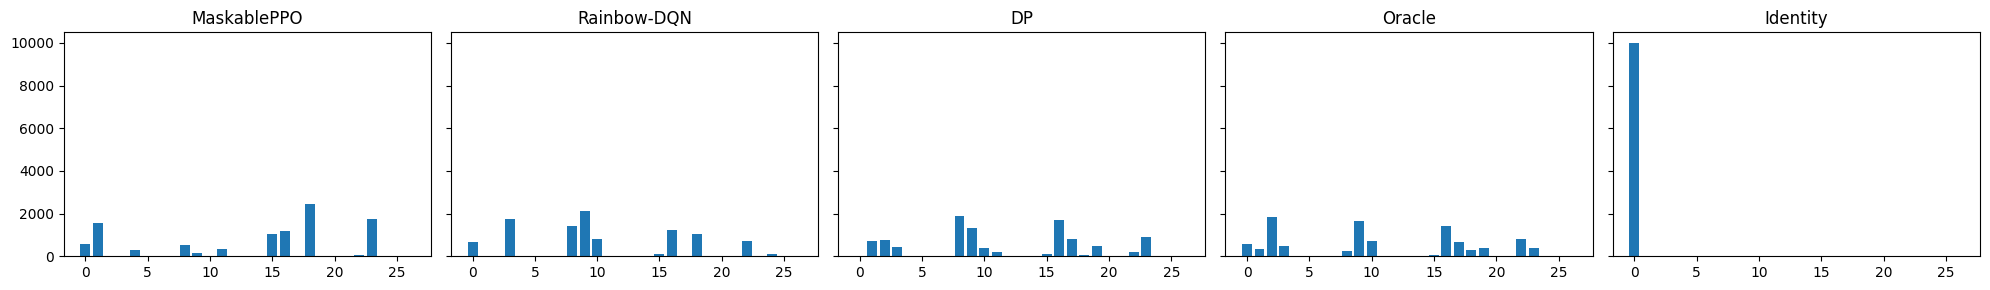

In [8]:
fig, axes = plt.subplots(1, len(POLICIES), figsize=(4*len(POLICIES), 3), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    counts = np.bincount(r['actions'], minlength=N_ACTIONS)
    ax.bar(range(N_ACTIONS), counts)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## Save

In [9]:
with open('e91_exp7_results.pkl', 'wb') as f:
    pickle.dump({'results': results,
                 'mppo_history': cb_m.history, 'rainbow_history': rainbow_history}, f)
print('Saved e91_exp7_results.pkl')

Saved e91_exp7_results.pkl
